# Component interpretation across k = 4, 6 and 8

This read-only notebook completes the preparation for the uniform interpretive review specified in the follow-up protocol. It reads published coefficients and regenerated full reference matrices; it does not fit models, edit labels, or write review decisions. Preparing this notebook does not complete the human review.

For every component ask the same questions: (1) Is there a specific linguistic pattern? (2) Do representative documents support that description? (3) Are contradictions or repeated formulas disclosed? Keep mixed components mixed. Previously inspected examples are development evidence, not a new independent test.


In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

current = Path.cwd()
ROOT = next((p for p in [current, *current.parents]
             if (p / "data/processed/model_corpus_v1.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the project root or notebooks directory.")

source = ROOT / "data/processed/model_corpus_v1.csv"
followup = json.loads((ROOT / "results/followup_audit_v1/manifest.json").read_text())
if hashlib.sha256(source.read_bytes()).hexdigest() != followup["source_sha256"]:
    raise ValueError("Model corpus differs from the frozen follow-up input.")

ref_dir = ROOT / "results/reference_numeric_v1"
reference_manifest = json.loads((ref_dir / "manifest.json").read_text())
for name, expected in reference_manifest["files_sha256"].items():
    if hashlib.sha256((ref_dir / name).read_bytes()).hexdigest() != expected:
        raise ValueError(f"Reference file checksum mismatch: {name}")
terms = np.array(json.loads((ref_dir / "vocabulary.json").read_text()))
corpus = pd.read_csv(source, keep_default_na=False)
if not corpus["execution_number"].is_unique:
    raise ValueError("Duplicate execution IDs in corpus.")

membership = pd.read_csv(ROOT / "results/followup_audit_v1/feature_groups.csv")
if membership["term"].duplicated().any() or set(membership["term"]) != set(terms):
    raise ValueError("Feature groups do not partition the vocabulary.")
lookup = {term: i for i, term in enumerate(terms)}
groups = [np.array([lookup[t] for t in part["term"]])
          for _, part in membership.groupby("group_id", sort=True)]
representatives = np.array([min(terms[g]) for g in groups])

H, W = {}, {}
for k in [4, 6, 8]:
    frame = pd.read_csv(ref_dir / f"topic_term_k{k}.csv.gz")
    if frame.columns.tolist() != terms.tolist() or frame.shape != (k, len(terms)):
        raise ValueError(f"Reference dimensions or vocabulary differ at k={k}.")
    H[k] = frame.to_numpy()
    if not np.isfinite(H[k]).all() or (H[k] < 0).any():
        raise ValueError("Invalid term weights.")
    np.testing.assert_allclose(np.linalg.norm(H[k], axis=1), 1, atol=1e-10)
    weights = pd.read_csv(ROOT / f"results/nmf_v2/document_weights_k{k}.csv")
    if len(weights) != followup.get("documents_modeled", 477):
        raise ValueError("Unexpected modeled-document count.")
    if not weights["execution_number"].is_unique:
        raise ValueError("Duplicate modeled execution IDs.")
    W[k] = weights.merge(corpus[["execution_number", "model_text", "model_word_count", "source_url"]],
                         on="execution_number", how="left", validate="one_to_one", indicator=True)
    if not W[k]["_merge"].eq("both").all():
        raise ValueError("Missing model text.")
if any(set(W[k]["execution_number"]) != set(W[6]["execution_number"]) for k in [4, 8]):
    raise ValueError("Modeled IDs differ across k.")
print("Verified: 477 modeled documents; 3,196 features; 3,011 display groups.")


Verified: 477 modeled documents; 3,196 features; 3,011 display groups.


## Leading feature groups

Groups combine features with identical full-corpus TF-IDF columns for display only. Fitting retains all features. Rank by mean member weight rounded to ten decimal places, then alphabetical representative. A word list is evidence to inspect, not a validated interpretation. The number of components is 18 in total, not 18 independent findings.


In [2]:
def leading_groups(k, topic, n=10):
    if k not in H or not 1 <= topic <= k:
        raise ValueError("Choose k=4/6/8 and a topic number within that k.")
    scores = np.array([H[k][topic - 1, g].mean() for g in groups])
    order = np.lexsort((representatives, -np.round(scores, 10)))[:n]
    return pd.DataFrame({
        "rank": np.arange(1, len(order) + 1),
        "feature_group": [" | ".join(sorted(terms[groups[i]])) for i in order],
        "mean_member_weight": scores[order],
    })

overview = pd.DataFrame([
    {"k": k, "topic": topic,
     "leading_groups": "; ".join(leading_groups(k, topic, 8)["feature_group"])}
    for k in [4, 6, 8] for topic in range(1, k + 1)
])
with pd.option_context("display.max_colwidth", None, "display.max_rows", 20):
    display(overview.set_index(["k", "topic"]))


leading_groups
k topic                                                                          
4 1                        sorry; thank; family; peace; lord; forgive; like; hope
  2              love; tell; strong; family love; care; stay strong; family; stay
  3                                   not; did; know; did not; say; want; no; man
  4                            thy; heaven; evil; kingdom; shall; art; thou; amen
6 1                        sorry; peace; forgive; hope; pain; god; family; caused
  2            love; tell; family love; tell family; care; want tell; mom; family
  3                                  not; did; know; did not; say; want; no; kill
  4                            thy; heaven; evil; kingdom; shall; amen; art; lord
  5                   thank; like; ready; like thank; warden; jesus; friends; yes
  6      strong; stay strong; stay; love; love stay; strong love; support; family
8 1                        sorry; peace; hope; forgive; pain; family; caused; god
  2         love; tell; family love; tell family; care; want tell; mom; everybody
  3                                 not; did; did not; know; say; want; kill; man
  4                       thy; heaven; kingdom; evil; shall; thou; art; thy earth
  5            jesus; lord; christ; lord jesus; jesus christ; praise; god; spirit
  6      strong; stay strong; stay; love stay; love; strong love; family; support
  7        ready; ready warden; warden; home; ready home; blessing; released; bye
  8            thank; like; like thank; friends; family; yes; support; want thank

## Cross-k lexical correspondence

Read each cell as full-vector cosine similarity. This is not a probability or a semantic equivalence test. There is no forced one-to-one match: one component may correspond to multiple components at another k. Comparisons use regenerated reference term vectors, not evidence that every random initialization has the same structure.


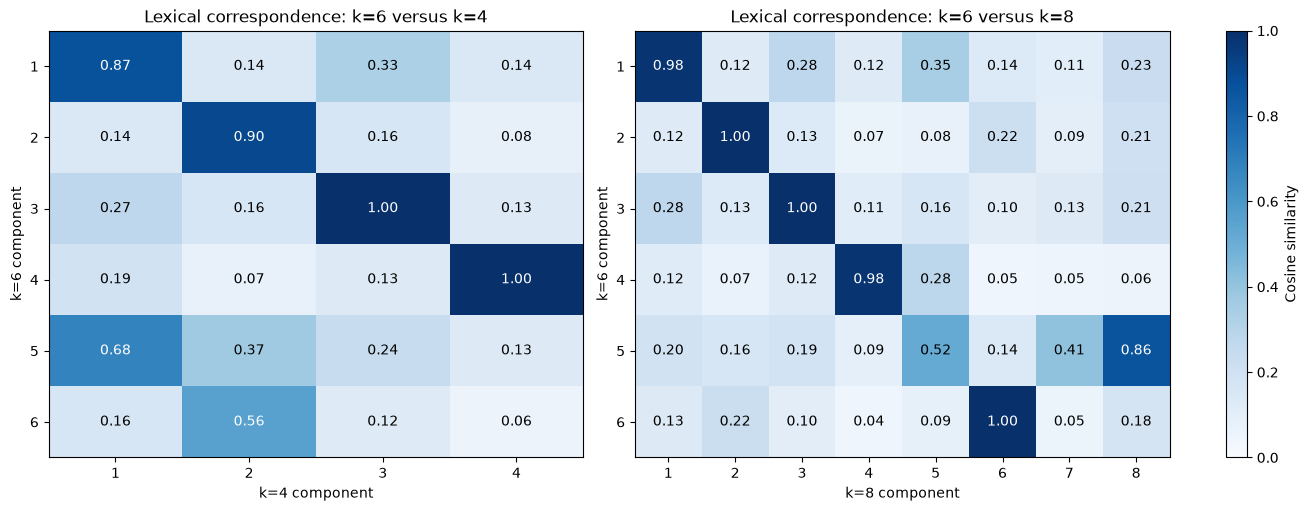

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, alternative_k in zip(axes, [4, 8]):
    similarity = H[6] @ H[alternative_k].T
    im = ax.imshow(similarity, vmin=0, vmax=1, cmap="Blues", aspect="auto")
    ax.set_xticks(range(alternative_k), labels=range(1, alternative_k + 1))
    ax.set_yticks(range(6), labels=range(1, 7))
    ax.set_xlabel(f"k={alternative_k} component")
    ax.set_ylabel("k=6 component")
    ax.set_title(f"Lexical correspondence: k=6 versus k={alternative_k}")
    for i in range(6):
        for j in range(alternative_k):
            ax.text(j, i, f"{similarity[i, j]:.2f}", ha="center", va="center",
                    color="white" if similarity[i, j] > 0.55 else "black")
fig.colorbar(im, ax=axes, label="Cosine similarity")
plt.show()


## Read documents before assigning a name

The default shows the three largest positive coefficients among documents of at least 20 words. This is a fixed display rule, not a corpus exclusion. It favors strong examples and cannot establish component-wide purity. Set `minimum_words=0` to include short documents and vary `offset` to inspect lower-ranked texts using the same ranking. Read beyond the first three before completing a review. Record execution IDs and short evidence excerpts when noting support or contradiction.


In [4]:
def show_component(k, topic, n_examples=3, minimum_words=20, offset=0):
    display(leading_groups(k, topic, 15))
    frame = W[k]
    coefficient = f"topic_{topic}"
    eligible = frame.loc[(frame[coefficient] > 0)
                         & frame["model_word_count"].ge(minimum_words)]
    ranked = eligible.sort_values([coefficient, "execution_number"], ascending=[False, True])
    selected = ranked.iloc[offset:offset + n_examples]
    print(f"k={k}, component={topic}; eligible documents={len(eligible)}")
    for _, row in selected.iterrows():
        print("\n" + "=" * 70)
        print(f"Execution {int(row['execution_number'])}; coefficient={row[coefficient]:.6f}")
        print("Source:", row["source_url"])
        print(row["model_text"])

show_component(6, 1)


,rank,feature_group,mean_member_weight
0,1,sorry,0.360488
1,2,peace,0.275808
2,3,forgive,0.254664
3,4,hope,0.229490
4,5,pain,0.215109
5,6,god,0.194327
6,7,family,0.184426
7,8,caused,0.179087
8,9,pray,0.146393
9,10,ask,0.130848


k=6, component=1; eligible documents=302

Execution 293; coefficient=0.394768
Source: https://www.tdcj.texas.gov/death_row/dr_info/curryalvalast.html
I pray with the help of God that you will forgive me for the pain I caused your family. I am truly sorry. I wish I could take it back, but I just pray and ask that you forgive me.

Execution 414; coefficient=0.391024
Source: https://www.tdcj.texas.gov/death_row/dr_info/murraywilliamlast.html
First I want to say to the family, I'm sorry I hope you find it in your heart to forgive me. The Lord has forgiven me. All I can say is I'm sorry. God Bless. To my family, I'll be there waiting for ya'll, alright? God Bless.

Execution 542; coefficient=0.368018
Source: https://www.tdcj.texas.gov/death_row/dr_info/bigbyjameslast.html
Yes, I do, Grace Kehler is that you? I have given Warden Jones a written statement that will explain a lot more. I hope this will bring you closure and answers to some questions. I hope this will bring you peace and I'm so

## Review notes to complete manually

For each (k, component), record: a narrow provisional description; supporting execution IDs and quotations; contradictory or ambiguous examples; repeated-formula influence; and whether the component remains mixed or unresolved. No suggested human labels are prefilled.

Start with k=6 components 1 and 4: is the first about apology, forgiveness, harm acknowledgment, or a mixture; does the fourth capture repeated prayer rather than broad faith? Then review the remaining components and compare k=4/8 using the same questions. Only after all 18 reviews should the protocol's interpretive part be marked complete. The existing frozen eight-label annotations remain unchanged.


In [5]:
# Inspect the next three strongest examples using the same selection rule.
show_component(6, 1, n_examples=3, minimum_words=20, offset=3)

,rank,feature_group,mean_member_weight
0,1,sorry,0.360488
1,2,peace,0.275808
2,3,forgive,0.254664
3,4,hope,0.229490
4,5,pain,0.215109
5,6,god,0.194327
6,7,family,0.184426
7,8,caused,0.179087
8,9,pray,0.146393
9,10,ask,0.130848


k=6, component=1; eligible documents=302

Execution 277; coefficient=0.360434
Source: https://www.tdcj.texas.gov/death_row/dr_info/medinajavierlast.html
First of all, I would like to apologize to the family members of the Cadena family for whatever hurt and suffering I have caused you. This opportunity has never come up before. It's not that I haven't been remorseful, things just never worked out before. Please forgive me and I hope you find it in your heart to forgive me. The peace you will find will be a temporary peace, true peace will come through find Christ. I pray through this execution, that you will find the peace you seek. Give yourself to Christ and find peace through him. I thought about your loved one very much. He will be waiting in heaven for me. I will be able to talk to him and ask him for forgiveness personally. To my family, I thank you and love you for being there for me and supporting me. This is just a stepping stone to home. The hardest part of all the years I wa

In [6]:
# Inspect three lower-ranked examples using the same eligibility rule.
# This is a diagnostic reading, not a representative sample.
show_component(
    6, 1,
    n_examples=3,
    minimum_words=20,
    offset=150,
)

,rank,feature_group,mean_member_weight
0,1,sorry,0.360488
1,2,peace,0.275808
2,3,forgive,0.254664
3,4,hope,0.229490
4,5,pain,0.215109
5,6,god,0.194327
6,7,family,0.184426
7,8,caused,0.179087
8,9,pray,0.146393
9,10,ask,0.130848


k=6, component=1; eligible documents=302

Execution 376; coefficient=0.098892
Source: https://www.tdcj.texas.gov/death_row/dr_info/matchettfarleylast.html
To my family and my mother and my three precious daughters, I love you all. And to my brother and sister for standing with me throughout this situation. Stay strong and know that I'm in a better place. I ask for forgiveness. And to the victim's family, find peace and cancellation with my death and move on. Our Lord Jesus Christ, I commend myself to you. I am ready.

Execution 482; coefficient=0.097835
Source: https://www.tdcj.texas.gov/death_row/dr_info/adamsbeunkalast.html
First, I want to let my mom know not to cry, there is no reason to cry, everybody dies. Everybody has their time, don't worry about me. I'm strong. To my family: my old man, my kids, daddy is sorry. I love each and every one of you. I'll be looking for you. To my wife, I love you. The last two years have been the best. All my kids, mom, nieces, and nephews, I am p

In [7]:
# Compare all six coefficients; these are not probabilities.
columns = ["execution_number"] + [
    f"topic_{topic}" for topic in range(1, 7)
]

display(
    W[6]
    .loc[W[6]["execution_number"].isin([376, 482, 77]), columns]
    .set_index("execution_number")
    .round(4)
)

# Examine the repeated-prayer component using the same display rule.
show_component(6, 4)

,topic_1,topic_2,topic_3,topic_4,topic_5,topic_6
execution_number,,,,,,
77,0.0974,0.0083,0.0000,0.0138,0.1364,0.0000
376,0.0989,0.0000,0.0000,0.0063,0.1319,0.2434
482,0.0978,0.0718,0.2284,0.0000,0.0000,0.1031


,rank,feature_group,mean_member_weight
0,1,thy,0.262624
1,2,heaven,0.149783
2,3,evil,0.144932
3,4,kingdom,0.143436
4,5,shall,0.136503
5,6,amen,0.134111
6,7,art,0.131651
7,8,lord,0.131543
8,9,thou,0.128882
9,10,forgive,0.116542


k=6, component=4; eligible documents=190

Execution 352; coefficient=0.830324
Source: https://www.tdcj.texas.gov/death_row/dr_info/whitemelvinlast.html
Tell Beth and them I am sorry, truly sorry for the pain that I caused your family. I truly mean that, too. She was a friend of mine and I betrayed her trust. I love you all. Tell momma I love her. The Lord is my shepherd; I shall not want, He maketh me to lie down in green pastures; he leadeth me beside the still waters. He restoreth my soul; he leadeth me in the paths of righteousness for his name's sake. Yea, though I walk through the valley of the shadow of death, I will fear no evil; for thou art with me. Thou preparest a table before me in the presence of mine enemies; thou anointest my head with oil; my cup runneth over. Surely goodness and mercy shall follow me all the days of my life; and I will dwell in the house of the Lord for ever. Our Father, who are in heaven, Hallowed be thy Name. Thy kingdom come. Thy will be done, On ea

In [8]:
# Lexical correspondence, not semantic equivalence.
similarity = pd.DataFrame(
    H[6] @ H[8].T,
    index=[f"k6_topic_{i}" for i in range(1, 7)],
    columns=[f"k8_topic_{i}" for i in range(1, 9)],
)

display(
    similarity.loc[["k6_topic_4", "k6_topic_5"]].round(3)
)

# Read the examples before interpreting the additional component.
show_component(8, 5)

,k8_topic_1,k8_topic_2,k8_topic_3,k8_topic_4,k8_topic_5,k8_topic_6,k8_topic_7,k8_topic_8
k6_topic_4,0.119,0.067,0.122,0.983,0.278,0.046,0.049,0.058
k6_topic_5,0.195,0.158,0.186,0.089,0.519,0.139,0.407,0.862


,rank,feature_group,mean_member_weight
0,1,jesus,0.416439
1,2,lord,0.411742
2,3,christ,0.252025
3,4,lord jesus,0.219336
4,5,jesus christ,0.198260
5,6,praise,0.181988
6,7,god,0.175098
7,8,spirit,0.140566
8,9,thank,0.130605
9,10,ask,0.126688


k=8, component=5; eligible documents=238

Execution 102; coefficient=0.415011
Source: https://www.tdcj.texas.gov/death_row/dr_info/vuonghailast.html
I thank God that he died for my sins on the cross, and I thank Him for saving my soul, so I will know when my body lays back in the grave, my soul goes to be with the Lord. Praise God. I hope whoever hears my voice tonight will turn to the Lord. I give my spirit back to Him. Praise the Lord. Praise Jesus. Hallelujah.

Execution 246; coefficient=0.389532
Source: https://www.tdcj.texas.gov/death_row/dr_info/goffdavidlast.html
I want to give all the praise to God and glory and thank him for all that he done for me. With this let all debts be paid that I owed - real or imagined. The slate is wiped clean, all marked erased other than that there is no justice. That's not justice. Praise the Lord. Glory to Jesus Christ. Praise the Lord God.

Execution 153; coefficient=0.388701
Source: https://www.tdcj.texas.gov/death_row/dr_info/boggesscliffordla

In [9]:
# Read the mixed component before interpreting cross-k correspondence.
show_component(6, 5)

,rank,feature_group,mean_member_weight
0,1,thank,0.414871
1,2,like,0.269794
2,3,ready,0.224851
3,4,like thank,0.213848
4,5,warden,0.201822
5,6,jesus,0.182028
6,7,friends,0.179155
7,8,yes,0.155865
8,9,family,0.152036
9,10,lord,0.142801


k=6, component=5; eligible documents=326

Execution 313; coefficient=0.411785
Source: https://www.tdcj.texas.gov/death_row/dr_info/murphyivanlast.html
Yes sir, I do. I would like to thank everybody for coming out tonight and celebrating life. This is a celebration of life, not death. Through Jesus Christ, we have victory over death. I would like to thank the Holy Father and Pope John Paul for their angelic blessings and all the prayers and support. And thanks to Father . and Guido Todeschini for your love and support. I want to thank everybody around the world and Father, let your will be done. I am going to keep this statement short. I love you all. I am ready, Warden.

Execution 569; coefficient=0.393884
Source: https://www.tdcj.texas.gov/death_row/dr_info/ochoaabellast.html
Yes sir. I would like to thank God, my dad, my Lord Jesus savior for saving me and changing my life. I want to apologize to my in-laws for causing all this emotional pain. I love y'all and consider y'all my siste

In [10]:
# Apply the same reading procedure to both candidate components.
show_component(8, 8)
show_component(8, 7)

,rank,feature_group,mean_member_weight
0,1,thank,0.422099
1,2,like,0.327254
2,3,like thank,0.255021
3,4,friends,0.211926
4,5,family,0.210678
5,6,yes,0.194289
6,7,support,0.172266
7,8,want thank,0.159304
8,9,warden,0.148200
9,10,apologize,0.131028


k=8, component=8; eligible documents=306

Execution 558; coefficient=0.427816
Source: https://www.tdcj.texas.gov/death_row/dr_info/brazielalvinlast.html
Yes Sir, I would like to thank the Shape Community Center for all their support. I would like to thank all those overseas, Italy and France, for their support for the death row prisoners. I would also like to apologize to Lori for the second time for her husband dying at my hand. To the White family and to Tashell for not being there, I Love you. I’m finished Warden you may proceed.

Execution 531; coefficient=0.407120
Source: https://www.tdcj.texas.gov/death_row/dr_info/holidayraphaellast.html
Yes, I would like to thank all of my supporters and loved ones. I love you, love y’all, always going to be with y’all. Thank you Warden.

Execution 345; coefficient=0.363787
Source: https://www.tdcj.texas.gov/death_row/dr_info/martinezalexanderlast.html
Yes. The victim's family is not here so I won't address them. I want to thank my family and f

,rank,feature_group,mean_member_weight
0,1,ready,0.716036
1,2,ready warden,0.321045
2,3,warden,0.275050
3,4,home,0.207267
4,5,ready home,0.166840
5,6,blessing,0.128780
6,7,released,0.121302
7,8,bye,0.115812
8,9,final,0.114795
9,10,no,0.113271


k=8, component=7; eligible documents=231

Execution 129; coefficient=0.452649
Source: https://www.tdcj.texas.gov/death_row/dr_info/stokerdavidlast.html
I have a statement prepared that I have given to the Chaplain that I want released to the media. I am ready, Warden.

Execution 398; coefficient=0.330329
Source: https://www.tdcj.texas.gov/death_row/dr_info/johnsonlonnielast.html
Yes I would. Carrie it's been a joy and a blessing. Take care, give everybody my regards. I love you, and I'll see you in eternity. Father take me home. I am ready to go.

Execution 461; coefficient=0.292507
Source: https://www.tdcj.texas.gov/death_row/dr_info/perrymichaellast.html
Yes, I want to start off by saying to everyone know that's involved in this atrocity that they are all forgiven by me. Mom, I love you… . I am ready to go Warden. Coming home dad, coming home dad.


In [11]:
# Inspect short documents with positive Topic 7 coefficients.
# Rank by coefficient, with execution number as the tie-breaker.
short_examples = (
    W[8]
    .loc[
        W[8]["model_word_count"].lt(10)
        & W[8]["topic_7"].gt(0),
        ["execution_number", "model_word_count", "topic_7", "model_text"],
    ]
    .sort_values(
        ["topic_7", "execution_number"],
        ascending=[False, True],
    )
    .head(10)
)

with pd.option_context("display.max_colwidth", None):
    display(short_examples)

,execution_number,model_word_count,topic_7,model_text
22,38,3,0.722408,"I’m ready, Warden."
407,525,5,0.520562,I'm ready to go home.
340,447,3,0.431856,"Bye, I'm ready."
199,285,7,0.404672,I am ready for the final blessing.
11,15,8,0.371426,I have no last words. I am ready.
77,133,9,0.349381,"Well, my friends in my heart, I’m ready –"
102,161,7,0.334203,I’m ready to be released. Release me.
362,475,6,0.157981,"No, I have no final statement."
19,34,9,0.014802,I wish everybody a good life. Everything is O.K.
292,396,8,0.001533,I love y'all and I'm gonna miss y'all.


In [12]:
# Describe coefficient concentration, not theme prevalence.
frame = W[8].copy()
frame["length_group"] = np.where(
    frame["model_word_count"].lt(10),
    "Under 10 words",
    "At least 10 words",
)
frame["positive_topic7"] = frame["topic_7"].gt(0)

summary = frame.groupby("length_group").agg(
    documents=("execution_number", "size"),
    positive_coefficients=("positive_topic7", "sum"),
    median_coefficient=("topic_7", "median"),
    coefficient_sum=("topic_7", "sum"),
)

total = frame["topic_7"].sum()
if total <= 0:
    raise ValueError("Topic 7 has no positive coefficient mass.")

summary["share_of_coefficient_sum_pct"] = (
    100 * summary["coefficient_sum"] / total
)
display(summary.round(4))

ranked = frame.sort_values(
    ["topic_7", "execution_number"],
    ascending=[False, True],
)

display(pd.DataFrame([
    {
        "top_n_documents": n,
        "under_10_words": int(
            ranked.head(n)["model_word_count"].lt(10).sum()
        ),
    }
    for n in [10, 20]
]))

,documents,positive_coefficients,median_coefficient,coefficient_sum,share_of_coefficient_sum_pct
length_group,,,,,
At least 10 words,456,245,0.0034,14.8663,81.7947
Under 10 words,21,10,0.0000,3.3088,18.2053


,top_n_documents,under_10_words
0,10,7
1,20,7


In [13]:
# Compare affection with encouragement using the same reading procedure.
show_component(6, 2)
show_component(6, 6)

,rank,feature_group,mean_member_weight
0,1,love,0.724475
1,2,tell,0.337054
2,3,family love,0.207732
3,4,tell family,0.164952
4,5,care,0.142882
5,6,want tell,0.123799
6,7,mom,0.120138
7,8,family,0.111922
8,9,everybody,0.111746
9,10,like tell,0.093137


k=6, component=2; eligible documents=320

Execution 201; coefficient=0.433388
Source: https://www.tdcj.texas.gov/death_row/dr_info/goodmanspencerlast.html
To my family, I love them. To Kami, I love you and will always be with you. That's it Warden.

Execution 399; coefficient=0.418913
Source: https://www.tdcj.texas.gov/death_row/dr_info/parrkennethlast.html
Can ya'll hear me? Tell my family that I love ya'll. Joe, Tim, everybody - keep your head up. I love you.

Execution 445; coefficient=0.386510
Source: https://www.tdcj.texas.gov/death_row/dr_info/simpsondaniellelast.html
Yeah, I want to tell my family I love y'all. Tell Kate I love her too. Tell brother, my kids I live y'all. I'm gonna miss y'all. I'm ready, ready.


,rank,feature_group,mean_member_weight
0,1,strong,0.500530
1,2,stay strong,0.464380
2,3,stay,0.459038
3,4,love,0.145997
4,5,love stay,0.140912
5,6,strong love,0.130506
6,7,support,0.110180
7,8,family,0.110159
8,9,thank support,0.100877
9,10,hour,0.095041


k=6, component=6; eligible documents=208

Execution 360; coefficient=0.710354
Source: https://www.tdcj.texas.gov/death_row/dr_info/hughestommielast.html
I love my family. You all stay strong. Watch over each other. Stay strong. I love you. I love you. It's my hour. It's my hour. I love you. Stay strong.

Execution 428; coefficient=0.584669
Source: https://www.tdcj.texas.gov/death_row/dr_info/ortizricardolast.html
I love my family. Thank you for all of your support. Stay strong. I am at peace. I love you and my kids. See you.

Execution 236; coefficient=0.503273
Source: https://www.tdcj.texas.gov/death_row/dr_info/chamberstonylast.html
Mom, I just want y'all to know that I love you. No matter what in life, I want you to stay strong. Doreen, you have been a very special part of my life, too. I want you to keep doing what you are doing. Stay strong. Dad, I want you to stay strong.


In [14]:
# Compare lexical correspondence without forcing a one-to-one match.
display(pd.DataFrame(
    H[4] @ H[6].T,
    index=[f"k4_topic_{i}" for i in range(1, 5)],
    columns=[f"k6_topic_{i}" for i in range(1, 7)],
).loc[["k4_topic_2"], ["k6_topic_2", "k6_topic_6"]].round(3))

# Inspect affection and encouragement coefficients for the same documents.
ids = [201, 399, 445, 360, 428, 236]
display(
    W[6]
    .loc[
        W[6]["execution_number"].isin(ids),
        ["execution_number", "topic_2", "topic_6"],
    ]
    .set_index("execution_number")
    .round(4)
)

show_component(4, 2)

,k6_topic_2,k6_topic_6
k4_topic_2,0.904,0.556


,topic_2,topic_6
execution_number,,
201,0.4334,0.0000
236,0.0000,0.5033
360,0.0000,0.7104
399,0.4189,0.0000
428,0.0319,0.5847
445,0.3865,0.0000


,rank,feature_group,mean_member_weight
0,1,love,0.652212
1,2,tell,0.256597
2,3,strong,0.193089
3,4,family love,0.153697
4,5,care,0.149830
5,6,stay strong,0.149560
6,7,family,0.148657
7,8,stay,0.146284
8,9,yes,0.142293
9,10,tell family,0.130412


k=4, component=2; eligible documents=350

Execution 560; coefficient=0.413602
Source: https://www.tdcj.texas.gov/death_row/dr_info/coblebillielast.html
Yes Sir, that will be five Dollars I love you, I love you, and I love you. Mike I love you. Where’s Nelley at? I love you. That will be five dollars. Take Care.”

Execution 201; coefficient=0.411184
Source: https://www.tdcj.texas.gov/death_row/dr_info/goodmanspencerlast.html
To my family, I love them. To Kami, I love you and will always be with you. That's it Warden.

Execution 374; coefficient=0.400162
Source: https://www.tdcj.texas.gov/death_row/dr_info/fullerjustinlast.html
Yes I do, I would like to tell my family thank you for your support, and my friends. And let everyone know that you must stay strong for each other. Take care of yourselves. That's it, Warden.


In [15]:
display(pd.DataFrame(
    H[4] @ H[6].T,
    index=[f"k4_topic_{i}" for i in range(1, 5)],
    columns=[f"k6_topic_{i}" for i in range(1, 7)],
).loc[["k4_topic_1"]].round(3))

show_component(4, 1)

,k6_topic_1,k6_topic_2,k6_topic_3,k6_topic_4,k6_topic_5,k6_topic_6
k4_topic_1,0.869,0.144,0.274,0.192,0.676,0.163


,rank,feature_group,mean_member_weight
0,1,sorry,0.251794
1,2,thank,0.219322
2,3,family,0.217838
3,4,peace,0.213758
4,5,lord,0.196009
5,6,forgive,0.192642
6,7,like,0.190324
7,8,hope,0.182982
8,9,god,0.176369
9,10,jesus,0.173863


k=4, component=1; eligible documents=356

Execution 277; coefficient=0.410714
Source: https://www.tdcj.texas.gov/death_row/dr_info/medinajavierlast.html
First of all, I would like to apologize to the family members of the Cadena family for whatever hurt and suffering I have caused you. This opportunity has never come up before. It's not that I haven't been remorseful, things just never worked out before. Please forgive me and I hope you find it in your heart to forgive me. The peace you will find will be a temporary peace, true peace will come through find Christ. I pray through this execution, that you will find the peace you seek. Give yourself to Christ and find peace through him. I thought about your loved one very much. He will be waiting in heaven for me. I will be able to talk to him and ask him for forgiveness personally. To my family, I thank you and love you for being there for me and supporting me. This is just a stepping stone to home. The hardest part of all the years I wa

In [16]:
# Compare case-related components across the two reference solutions.
display(pd.DataFrame(
    H[4] @ H[6].T,
    index=[f"k4_topic_{i}" for i in range(1, 5)],
    columns=[f"k6_topic_{i}" for i in range(1, 7)],
).loc[["k4_topic_3"]].round(3))

show_component(4, 3)
show_component(6, 3)

,k6_topic_1,k6_topic_2,k6_topic_3,k6_topic_4,k6_topic_5,k6_topic_6
k4_topic_3,0.332,0.164,0.996,0.13,0.238,0.123


,rank,feature_group,mean_member_weight
0,1,not,0.362129
1,2,did,0.276385
2,3,know,0.253487
3,4,did not,0.232227
4,5,say,0.189006
5,6,want,0.176458
6,7,no,0.144244
7,8,man,0.130057
8,9,kill,0.128519
9,10,just,0.128384


k=4, component=3; eligible documents=336

Execution 367; coefficient=0.408524
Source: https://www.tdcj.texas.gov/death_row/dr_info/reeselamontlast.html
Yeah. Momma, I just want you to know I love you. I want all of you to know I love you all. I am at peace; we know what it is. We know the truth. Stay out of crime; there is no point in it. I am at peace. We know the truth and I know it. I have some peace. I am glad it didn't take that long - no 10 or 20 years. I am at peace. And I want everyone to know I did not walk to this because this is straight up murder. I just want everybody to know I didn't walk to this. The reason is because it's murder. I am not going to play a part in my own murder. No one should have to do that. I love you all. I do not know all of your names. And I don't know how you feel about me. And whether you believe it or not, I did not kill them. I just want you all to have peace; you know what I'm saying. There is no point in that. It is neither here nor there. You 

,rank,feature_group,mean_member_weight
0,1,not,0.364170
1,2,did,0.290785
2,3,know,0.253676
3,4,did not,0.252683
4,5,say,0.181888
5,6,want,0.174440
6,7,no,0.148358
7,8,kill,0.144079
8,9,man,0.134476
9,10,not kill,0.127078


k=6, component=3; eligible documents=322

Execution 367; coefficient=0.413097
Source: https://www.tdcj.texas.gov/death_row/dr_info/reeselamontlast.html
Yeah. Momma, I just want you to know I love you. I want all of you to know I love you all. I am at peace; we know what it is. We know the truth. Stay out of crime; there is no point in it. I am at peace. We know the truth and I know it. I have some peace. I am glad it didn't take that long - no 10 or 20 years. I am at peace. And I want everyone to know I did not walk to this because this is straight up murder. I just want everybody to know I didn't walk to this. The reason is because it's murder. I am not going to play a part in my own murder. No one should have to do that. I love you all. I do not know all of your names. And I don't know how you feel about me. And whether you believe it or not, I did not kill them. I just want you all to have peace; you know what I'm saying. There is no point in that. It is neither here nor there. You 

In [17]:
print(
    "Cross-k cosine:",
    round(float(H[4][3] @ H[8][3]), 3),
)

show_component(4, 4)
show_component(8, 4)

Cross-k cosine: 0.989


,rank,feature_group,mean_member_weight
0,1,thy,0.265262
1,2,heaven,0.150772
2,3,evil,0.145804
3,4,kingdom,0.144054
4,5,shall,0.138288
5,6,art,0.133095
6,7,thou,0.130751
7,8,amen,0.130303
8,9,lord,0.112629
9,10,thy earth,0.110752


k=4, component=4; eligible documents=199

Execution 352; coefficient=0.838950
Source: https://www.tdcj.texas.gov/death_row/dr_info/whitemelvinlast.html
Tell Beth and them I am sorry, truly sorry for the pain that I caused your family. I truly mean that, too. She was a friend of mine and I betrayed her trust. I love you all. Tell momma I love her. The Lord is my shepherd; I shall not want, He maketh me to lie down in green pastures; he leadeth me beside the still waters. He restoreth my soul; he leadeth me in the paths of righteousness for his name's sake. Yea, though I walk through the valley of the shadow of death, I will fear no evil; for thou art with me. Thou preparest a table before me in the presence of mine enemies; thou anointest my head with oil; my cup runneth over. Surely goodness and mercy shall follow me all the days of my life; and I will dwell in the house of the Lord for ever. Our Father, who are in heaven, Hallowed be thy Name. Thy kingdom come. Thy will be done, On ea

,rank,feature_group,mean_member_weight
0,1,thy,0.270289
1,2,heaven,0.150648
2,3,kingdom,0.146620
3,4,evil,0.145531
4,5,shall,0.139376
5,6,thou,0.138838
6,7,art,0.137770
7,8,thy earth,0.112086
8,9,forgive,0.110676
9,10,amen,0.110250


k=8, component=4; eligible documents=180

Execution 352; coefficient=0.859847
Source: https://www.tdcj.texas.gov/death_row/dr_info/whitemelvinlast.html
Tell Beth and them I am sorry, truly sorry for the pain that I caused your family. I truly mean that, too. She was a friend of mine and I betrayed her trust. I love you all. Tell momma I love her. The Lord is my shepherd; I shall not want, He maketh me to lie down in green pastures; he leadeth me beside the still waters. He restoreth my soul; he leadeth me in the paths of righteousness for his name's sake. Yea, though I walk through the valley of the shadow of death, I will fear no evil; for thou art with me. Thou preparest a table before me in the presence of mine enemies; thou anointest my head with oil; my cup runneth over. Surely goodness and mercy shall follow me all the days of my life; and I will dwell in the house of the Lord for ever. Our Father, who are in heaven, Hallowed be thy Name. Thy kingdom come. Thy will be done, On ea

In [18]:
# Check whether the apology and case-related mixtures persist at k=8.
show_component(8, 1)
show_component(8, 3)

,rank,feature_group,mean_member_weight
0,1,sorry,0.391543
1,2,peace,0.301808
2,3,hope,0.259152
3,4,forgive,0.245398
4,5,pain,0.222780
5,6,family,0.193025
6,7,caused,0.185293
7,8,god,0.154753
8,9,pray,0.137390
9,10,pain caused,0.133243


k=8, component=1; eligible documents=286

Execution 293; coefficient=0.394871
Source: https://www.tdcj.texas.gov/death_row/dr_info/curryalvalast.html
I pray with the help of God that you will forgive me for the pain I caused your family. I am truly sorry. I wish I could take it back, but I just pray and ask that you forgive me.

Execution 414; coefficient=0.365175
Source: https://www.tdcj.texas.gov/death_row/dr_info/murraywilliamlast.html
First I want to say to the family, I'm sorry I hope you find it in your heart to forgive me. The Lord has forgiven me. All I can say is I'm sorry. God Bless. To my family, I'll be there waiting for ya'll, alright? God Bless.

Execution 433; coefficient=0.359684
Source: https://www.tdcj.texas.gov/death_row/dr_info/morriskennethlast.html
Yes, I have to say that I am sorry for all the pain that I have caused you and your family. I only have love in my heart. I hope that you can all forgive me. I pray that you can all forgive me. Thank you for standing by

,rank,feature_group,mean_member_weight
0,1,not,0.366446
1,2,did,0.295893
2,3,did not,0.261623
3,4,know,0.261023
4,5,say,0.173796
5,6,want,0.172680
6,7,kill,0.150566
7,8,man,0.134783
8,9,not kill,0.133379
9,10,no,0.128075


k=8, component=3; eligible documents=317

Execution 152; coefficient=0.413512
Source: https://www.tdcj.texas.gov/death_row/dr_info/munizpedrolast.html
I know you can’t hear me now but I know that it won’t matter what I have to say. I want you to know that I did not kill your sister. If you want to know the truth, and you deserve to know the truth, hire your own investigators. That’s all I have to say.

Execution 391; coefficient=0.413342
Source: https://www.tdcj.texas.gov/death_row/dr_info/clarkjameslast.html
Uh, I don't know, Um, I don't know what to say. I don't know. . I didn't know anybody was there. Howdy.

Execution 367; coefficient=0.411318
Source: https://www.tdcj.texas.gov/death_row/dr_info/reeselamontlast.html
Yeah. Momma, I just want you to know I love you. I want all of you to know I love you all. I am at peace; we know what it is. We know the truth. Stay out of crime; there is no point in it. I am at peace. We know the truth and I know it. I have some peace. I am glad it d

In [19]:
show_component(8, 2)
show_component(8, 6)

,rank,feature_group,mean_member_weight
0,1,love,0.731908
1,2,tell,0.339328
2,3,family love,0.204324
3,4,tell family,0.165170
4,5,care,0.139803
5,6,want tell,0.124681
6,7,mom,0.120616
7,8,everybody,0.108150
8,9,family,0.104697
9,10,like tell,0.088840


k=8, component=2; eligible documents=314

Execution 201; coefficient=0.418447
Source: https://www.tdcj.texas.gov/death_row/dr_info/goodmanspencerlast.html
To my family, I love them. To Kami, I love you and will always be with you. That's it Warden.

Execution 399; coefficient=0.417829
Source: https://www.tdcj.texas.gov/death_row/dr_info/parrkennethlast.html
Can ya'll hear me? Tell my family that I love ya'll. Joe, Tim, everybody - keep your head up. I love you.

Execution 445; coefficient=0.367393
Source: https://www.tdcj.texas.gov/death_row/dr_info/simpsondaniellelast.html
Yeah, I want to tell my family I love y'all. Tell Kate I love her too. Tell brother, my kids I live y'all. I'm gonna miss y'all. I'm ready, ready.


,rank,feature_group,mean_member_weight
0,1,strong,0.504678
1,2,stay strong,0.468730
2,3,stay,0.462471
3,4,love stay,0.142901
4,5,love,0.141055
5,6,strong love,0.132429
6,7,family,0.104303
7,8,support,0.100103
8,9,hour,0.097307
9,10,thank support,0.095294


k=8, component=6; eligible documents=195

Execution 360; coefficient=0.715310
Source: https://www.tdcj.texas.gov/death_row/dr_info/hughestommielast.html
I love my family. You all stay strong. Watch over each other. Stay strong. I love you. I love you. It's my hour. It's my hour. I love you. Stay strong.

Execution 428; coefficient=0.570628
Source: https://www.tdcj.texas.gov/death_row/dr_info/ortizricardolast.html
I love my family. Thank you for all of your support. Stay strong. I am at peace. I love you and my kids. See you.

Execution 236; coefficient=0.506853
Source: https://www.tdcj.texas.gov/death_row/dr_info/chamberstonylast.html
Mom, I just want y'all to know that I love you. No matter what in life, I want you to stay strong. Doreen, you have been a very special part of my life, too. I want you to keep doing what you are doing. Stay strong. Dad, I want you to stay strong.
